# 01 Neural-network tutorial
Toy examples (polynomial fits, autograd, optimizers, a small ReLU exercise) used to learn PyTorch. Not part of the project results.

In [ ]:
# notebooks live in notebooks/, the project modules in the repo root
import sys
if '..' not in sys.path:
    sys.path.insert(0, '..')

%load_ext autoreload
%autoreload 2

# standard libraries
import math

# third-party
import numpy as np
import pandas as pd
import torch
import seaborn as sns
from matplotlib import pyplot as plt

# project modules
import benchmarks as bm
from model import Policy
from market.simulators import simulate_heston, simulate_gbm, HestonParams
from market.pricing import bs_price, bs_delta, bs_gamma, heston_price

# Toy Example of Neural Network

*Fit sin(x) with a cubic polynomial by hand-coded gradient descent in numpy.*

In [7]:
## Learning with numpy, suppose using a+bx+cx^2+dx^3 to approximate sin(x)
x = np.linspace(-np.pi, np.pi, 2000)
y = np.sin(x)

rng = np.random.default_rng(0)
a, b, c, d = rng.normal(size = 4)
learning_rate = 1e-6

# Gradient descent
for t in range(2000):
    y_pred = a + b * x + c * x ** 2 + d * x ** 3

    loss = np.square(y_pred - y).sum()
    if t % 400 == 99:
        print(t, loss)

    ## Gradient descent
    grad_y_pred = 2 * (y_pred - y)
    grad_a = grad_y_pred.sum()
    grad_b = (grad_y_pred * x).sum()
    grad_c = (grad_y_pred * x ** 2).sum()
    grad_d = (grad_y_pred * x ** 3).sum()

    ## Updating
    a -= learning_rate * grad_a
    b -= learning_rate * grad_b
    c -= learning_rate * grad_c
    d -= learning_rate * grad_d

print(f'Result: y = {a} + {b} x + {c} x^2 + {d} x^3')

99 704.3593016451537
499 141.80561551956498
899 34.24523948649255
1299 13.679266905470849
1699 9.746878637823649
Result: y = 0.00046628585139411177 + 0.8408077414722543 x + -8.044206839554327e-05 x^2 + -0.09106404408445065 x^3


*Same fit with torch tensors, gradients still computed by hand.*

In [8]:
## Learning with PyTorch Tensors
dtype = torch.float
device = torch.device("cpu")

x = torch.linspace(-torch.pi, torch.pi, 2000, device = device, dtype = dtype)
y = torch.sin(x)

# Randomly initialize weights
a = torch.randn((), device=device, dtype=dtype)
b = torch.randn((), device=device, dtype=dtype)
c = torch.randn((), device=device, dtype=dtype)
d = torch.randn((), device=device, dtype=dtype)

learning_rate = 1e-6
for t in range(2000):
    # Forward pass: compute predicted y
    y_pred = a + b * x + c * x ** 2 + d * x ** 3

    # Compute and print loss
    loss = (y_pred - y).pow(2).sum().item()
    if t % 200 == 99:
        print(t, loss)

    # Backprop to compute gradients of a, b, c, d with respect to loss
    grad_y_pred = 2.0 * (y_pred - y)
    grad_a = grad_y_pred.sum()
    grad_b = (grad_y_pred * x).sum()
    grad_c = (grad_y_pred * x ** 2).sum()
    grad_d = (grad_y_pred * x ** 3).sum()

    # Update weights using gradient descent
    a -= learning_rate * grad_a
    b -= learning_rate * grad_b
    c -= learning_rate * grad_c
    d -= learning_rate * grad_d


print(f'Result: y = {a.item()} + {b.item()} x + {c.item()} x^2 + {d.item()} x^3')


99 1875.955810546875
299 929.794921875
499 463.8821716308594
699 234.01858520507812
899 120.41900634765625
1099 64.1915054321289
1299 36.32289505004883
1499 22.493247985839844
1699 15.622920036315918
1899 12.206560134887695
Result: y = 0.050842270255088806 + 0.8477590680122375 x + -0.008771137334406376 x^2 + -0.09205280989408493 x^3


## Tensor and Autograd

*Fit exp(x) with a cubic using autograd (requires_grad + backward).*

In [9]:
## Find degree 3 polynomial for exp(x)
x = torch.linspace(-1, 1, 1000, dtype = dtype)
y = torch.exp(x)

# Setting requires_grad=True indicates that we want to compute gradients with
# respect to these Tensors during the backward pass.
a = torch.randn((), dtype=dtype, requires_grad=True)
b = torch.randn((), dtype=dtype, requires_grad=True)
c = torch.randn((), dtype=dtype, requires_grad=True)
d = torch.randn((), dtype=dtype, requires_grad=True)

inital_loss = 1
learning_rate = 1e-5
for t in range(5000):
    y_pred = a + b * x + c * x ** 2 + d * x ** 3
    loss = (y_pred - y).pow(2).sum()

    if t % 200 == 99:
        print(f'Iteration t = {t:4d}  loss(t) = {round(loss.item(), 6):10.6f}  a = {a.item():10.6f}  b = {b.item():10.6f}  c = {c.item():10.6f}  d = {d.item():10.6f}')

    # Use autograd to compute the backward pass. This call will compute the
    # gradient of loss with respect to all Tensors with requires_grad=True.
    # After this call a.grad, b.grad. c.grad and d.grad will be Tensors holding
    # the gradient of the loss with respect to a, b, c, d respectively.

    loss.backward()

    # --- autograd ---
    # autograd is PyTorch's automatic differentiation (its implementation of backprop).
    # 1. Forward: every operation involving a tensor with requires_grad=True is recorded
    #    in a computational graph ("what was computed from what").
    # 2. loss.backward(): walks the graph in reverse, applies the chain rule, and stores
    #    dL/dparam in param.grad for every parameter.
    # Gradients ACCUMULATE: each backward() adds to .grad, so .grad must be reset
    # (param.grad = None, or optimizer.zero_grad()) before the next backward().

    # --- with / torch.no_grad() ---
    # `with` runs setup on entering the indented block and undoes it on leaving
    # (even if an error occurs).
    # torch.no_grad() turns off autograd recording inside the block, and turns it back on afterwards.
    #
    # Why the parameter update must be inside no_grad():
    # autograd records ANY operation on requires_grad tensors; it cannot tell
    # "model computation" from "parameter update". If the update were recorded:
    #   - the new parameter would depend on the old one, so backward() would differentiate
    #     through every past update (gradient w.r.t. the INITIAL parameters, not the current ones);
    #   - the graph would grow every step (slower, more memory);
    #   - an in-place update (a -= ...) on a leaf tensor raises a RuntimeError.
    #
    # Use no_grad() for: parameter updates, evaluation on a test set.
    # Never use it in the training forward pass (e.g. the hedging rollout): it would cut the
    # gradient chain, and the parameters would receive no gradient.
    with torch.no_grad():
        a -= learning_rate * a.grad
        b -= learning_rate * b.grad
        c -= learning_rate * c.grad
        d -= learning_rate * d.grad

        a.grad = None
        b.grad = None
        c.grad = None
        d.grad = None

print(f'Result: y = {a.item()} + {b.item()} x + {c.item()} x^2 + {d.item()} x^3')

Iteration t =   99  loss(t) = 167.590759  a =   1.235583  b =   0.456998  c =  -0.648186  d =   0.809978
Iteration t =  299  loss(t) =  70.245979  a =   1.291014  b =   0.569666  c =  -0.281035  d =   0.818340
Iteration t =  499  loss(t) =  40.501030  a =   1.211885  b =   0.609475  c =  -0.057408  d =   0.784658
Iteration t =  699  loss(t) =  24.425327  a =   1.153068  b =   0.636432  c =   0.104735  d =   0.746638
Iteration t =  899  loss(t) =  15.552251  a =   1.110286  b =   0.660038  c =   0.222629  d =   0.710049
Iteration t = 1099  loss(t) =  10.532348  a =   1.079177  b =   0.681870  c =   0.308355  d =   0.675659
Iteration t = 1299  loss(t) =   7.590692  a =   1.056557  b =   0.702255  c =   0.370689  d =   0.643461
Iteration t = 1499  loss(t) =   5.783718  a =   1.040109  b =   0.721319  c =   0.416014  d =   0.613335
Iteration t = 1699  loss(t) =   4.608069  a =   1.028149  b =   0.739154  c =   0.448971  d =   0.585151
Iteration t = 1899  loss(t) =   3.793715  a =   1.01945

## Use Neural Network

*Cubic fit written as nn.Sequential with a manual parameter update loop.*

In [10]:
## getting back to the sin(x) example
x = torch.linspace(-torch.pi, torch.pi, 2000)
y = torch.sin(x)

p = torch.tensor([1,2,3])
xx = x.unsqueeze(-1).pow(p) ## each row is [x, x^2, x^3]

## nn.Sequential stores the structure of the nn
model = torch.nn.Sequential(
    torch.nn.Linear(3, 1),
    torch.nn.Flatten(0,1)
)
loss_fn = torch.nn.MSELoss(reduction = 'sum')
learning_rate = 1e-6

for t in range(2000):
    y_pred = model(xx)
    loss = loss_fn(y_pred, y)
    model.zero_grad() ## emptying all calculated gradient, equivalent to a.grad = None
    loss.backward()
    with torch.no_grad():
        for param in model.parameters():
            param -= learning_rate * param.grad

linear_layer = model[0]
# For linear layer, its parameters are stored as `weight` and `bias`.
print(f'Result: y = {linear_layer.bias.item()} + {linear_layer.weight[:, 0].item()} x + {linear_layer.weight[:, 1].item()} x^2 + {linear_layer.weight[:, 2].item()} x^3')

Result: y = 0.008391104638576508 + 0.8336213231086731 x + -0.0014476045034825802 x^2 + -0.09004183858633041 x^3


## NN with Optim

*Same model trained with torch.optim.Adam (zero_grad / backward / step).*

In [11]:
x = torch.linspace(-torch.pi, torch.pi, 2000)
y = torch.sin(x)

p = torch.tensor([1,2,3])
xx = x.unsqueeze(-1).pow(p) ## each row is [x, x^2, x^3]

## nn.Sequential stores the structure of the nn
model = torch.nn.Sequential(
    torch.nn.Linear(3, 1),
    torch.nn.Flatten(0,1)
)
loss_fn = torch.nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr = 1e-3)

for t in range(2000):
    y_pred = model(xx)
    loss = loss_fn(y_pred, y)
    if t % 500 == 0:
        print(f'Current loss: {loss}')
    optimizer.zero_grad() ## emptying all calculated gradient, equivalent to a.grad = None
    loss.backward()
    optimizer.step()

linear_layer = model[0]
# For linear layer, its parameters are stored as `weight` and `bias`.
print(f'Result: y = {linear_layer.bias.item()} + {linear_layer.weight[:, 0].item()} x + {linear_layer.weight[:, 1].item()} x^2 + {linear_layer.weight[:, 2].item()} x^3')

Current loss: 21.964859008789062
Current loss: 1.4165408611297607
Current loss: 0.9535034894943237
Current loss: 0.6850067973136902
Result: y = -0.04943632706999779 + -0.054648321121931076 x + 0.009375505149364471 x^2 + 0.03908925503492355 x^3


## Customized NN

*Custom nn.Module with four nn.Parameter coefficients.*

In [12]:
class Polynomial3(torch.nn.Module):
    def __init__(self):
        super().__init__()
        self.a = torch.nn.Parameter(torch.randn(()))
        self.b = torch.nn.Parameter(torch.randn(()))
        self.c = torch.nn.Parameter(torch.randn(()))
        self.d = torch.nn.Parameter(torch.randn(()))

    def forward(self, x):
        return self.a + self.b * x + self.c * x ** 2 + self.d * x ** 3

    def string(self):
        return f'y = {self.a.item()} + {self.b.item()} x + {self.c.item()} x^2 + {self.d.item()} x^3'

# Create Tensors to hold input and outputs.
x = torch.linspace(-torch.pi, torch.pi, 2000)
y = torch.sin(x)

# Construct our model by instantiating the class defined above
model = Polynomial3()

# Construct our loss function and an Optimizer. The call to model.parameters()
# in the SGD constructor will contain the learnable parameters (defined 
# with torch.nn.Parameter) which are members of the model.
criterion = torch.nn.MSELoss(reduction='sum')
optimizer = torch.optim.SGD(model.parameters(), lr=1e-6)
for t in range(2000):
    # Forward pass: Compute predicted y by passing x to the model
    y_pred = model(x)

    # Compute and print loss
    loss = criterion(y_pred, y)
    if t % 100 == 99:
        print(t, loss.item())

    # Zero gradients, perform a backward pass, and update the weights.
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

print(f'Result: {model.string()}')

99 2440.637939453125
199 1643.42822265625
299 1108.5126953125
399 749.30126953125
499 507.88128662109375
599 345.4887390136719
699 236.15814208984375
799 162.4841766357422
899 112.79154968261719
999 79.24173736572266
1099 56.56825256347656
1199 41.22956848144531
1299 30.842220306396484
1399 23.800416946411133
1499 19.02149200439453
1599 15.774650573730469
1699 13.56635570526123
1799 12.062691688537598
1899 11.0376558303833
1999 10.338103294372559
Result: y = -0.02998986653983593 + 0.8306897878646851 x + 0.005173752084374428 x^2 + -0.08962485194206238 x^3


## Exercise

*Exercise: learn clamp(x, 0, 1) with a 1-16-1 ReLU network; compare predictions at test points.*

Current loss: 0.7274301648139954
Current loss: 0.007844489067792892
Current loss: 0.0016141055384650826
Current loss: 0.0006995050352998078
Current loss: 0.0002919293474406004
Current loss: 0.00010408711386844516
x = -0.50   model = -0.0071   true =  0.00
x =  0.00   model =  0.0442   true =  0.00
x =  0.50   model =  0.4989   true =  0.50
x =  1.00   model =  0.9830   true =  1.00
x =  1.50   model =  0.9974   true =  1.00


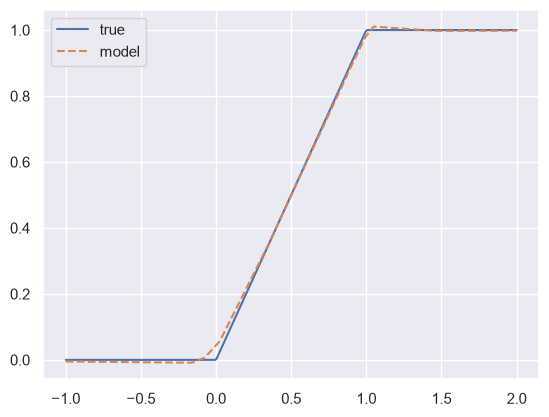

In [13]:
## use the clip function
x = torch.linspace(-5, 5, 2000).unsqueeze(-1)
y = torch.clamp(x, min = 0, max = 1)

model = torch.nn.Sequential(
    torch.nn.Linear(1, 16),
    torch.nn.ReLU(),
    torch.nn.Linear(16, 1)
)

loss_fn = torch.nn.MSELoss(reduction = 'mean')
optimizer = torch.optim.Adam(model.parameters(), lr = 1e-3)

for t in range(3000):
    y_pred = model(x)
    loss = loss_fn(y_pred, y)
    if t % 500 == 0:
        print(f'Current loss: {loss}')
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

x_test = torch.tensor([-0.5, 0, 0.5, 1, 1.5]).unsqueeze(-1)
with torch.no_grad():
    y_hat = model(x_test)
y_true = torch.clamp(x_test, min = 0, max = 1)

for xi, yh, yt in zip(x_test.squeeze(-1), y_hat.squeeze(-1), y_true.squeeze(-1)):
    print(f"x = {xi:5.2f}   model = {yh:7.4f}   true = {yt:5.2f}")


x_plot = torch.linspace(-1, 2, 300).unsqueeze(-1)    # (300, 1)
with torch.no_grad():
    y_plot = model(x_plot)

plt.plot(x_plot.squeeze(-1), x_plot.clamp(0, 1).squeeze(-1), label="true")
plt.plot(x_plot.squeeze(-1), y_plot.squeeze(-1), "--", label="model")
plt.legend()
plt.show()

*Same exercise with only 2 hidden units over 5 seeds: dead-ReLU / bad-initialization failures.*

In [14]:
## use the clip function
x = torch.linspace(-5, 5, 2000).unsqueeze(-1)
y = torch.clamp(x, min = 0, max = 1)


loss_fn = torch.nn.MSELoss(reduction = 'mean')
## Test on different seeds
for seed in range(5):
    torch.manual_seed(seed)
    model = torch.nn.Sequential(
        torch.nn.Linear(1,2),
        torch.nn.ReLU(),
        torch.nn.Linear(2,1)
    )

    optimizer = torch.optim.Adam(model.parameters(), lr = 1e-3)

    for t in range(3000):
        y_pred = model(x)
        loss = loss_fn(y_pred, y)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    print(f'Final Loss with seed {seed}: {loss}')

Final Loss with seed 0: 0.0350605733692646
Final Loss with seed 1: 0.04603457823395729
Final Loss with seed 2: 0.029540229588747025
Final Loss with seed 3: 0.0017115657683461905
Final Loss with seed 4: 0.2308439463376999
